# Expansion Data 
This code will recreate figure panels as well as plot individual dendrites and determine summary values of key variables
>>  mean diam <br>
>>  length <br>
>>  distance <br>
>>   resistance <br>


In [ ]:
import sys
import matplotlib.pyplot as plt
plt.rc("axes.spines", top=False, right=False)

import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
#%load_ext autoreload
#%autoreload 2

import os
import glob

plot_path="../output/plots"
mypath = plot_path

import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc, summary_compt, avgCDF
from plots import plot_dsc

## Load dendritic diameter data
Set location of repo data (root folder) sets the paths for each expanded dendrite analysed

In [ ]:
from pathlib import Path
root = 'E:/Bonn/Data/Distal_Dendrite/Morphology/'

ExMdata={}

ExMdata['dendrite1'] = {'path':root+'repo_data/ExM/2016_07_07/branch1/tables/2016_07_07_slice4_left_branch1_Local Diameter.csv'}
ExMdata['dendrite1']['file']= '2016_07_07_slice4_left_branch1_Local Diameter.csv'
ExMdata['dendrite1']['ex_factor'] = 4.1
ExMdata['dendrite1']['res'] = 1

#sub-branch of branch 3 
# ExMdata['dendrite2'] = {'path':''M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/ExM/2016_07_07/branch2/tables/2016_07_07_slice4_left_branch2_Local Diameter.csv'}
# ExMdata['dendrite2']['file']= '2016_07_07_slice4_left_branch2_Local Diameter.csv'
# ExMdata['dendrite2']['ex_factor'] = 4.1
# ExMdata['demdrite2']['res'] = 1

ExMdata['dendrite3'] = {'path':root+'repo_data/ExM/2016_07_07/branch3/tables/2016_07_07_slice4_left_branch3_Local Diameter.csv'}
ExMdata['dendrite3']['file']= '2016_07_07_slice4_left_branch3_Local Diameter.csv'
ExMdata['dendrite3']['ex_factor'] = 4.1
ExMdata['dendrite3']['res'] = 1

ExMdata['dendrite4'] = {'path':root+'repo_data/ExM/2019_05_04/branch4/tables/2019_05_04_slice3_side1_branch4_localDiameter.csv'}
ExMdata['dendrite4']['file']= '2019_05_04_slice3_side1_branch4_localDiameter.csv'
ExMdata['dendrite4']['ex_factor'] = 4.1
ExMdata['dendrite4']['res'] = 1

ExMdata['C1_02_cell1_d2'] = {'path':root+'repo_data/ExM/2020_06_08/T1_02/tables/20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'}
ExMdata['C1_02_cell1_d2']['file']= '20210201_DG-T1_AF488-02_neuron01_8bit_1000-3000_dend2 - Local Diameter.csv'
ExMdata['C1_02_cell1_d2']['ex_factor'] = 3.8
ExMdata['C1_02_cell1_d2']['res'] = 0.173

ExMdata['C1_03_cell2_d2'] = {'path':root+'repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'}
ExMdata['C1_03_cell2_d2']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend2 - Local Diameter.csv'
ExMdata['C1_03_cell2_d2']['ex_factor'] = 3.8
ExMdata['C1_03_cell2_d2']['res'] = 0.173

ExMdata['C1_03_cell2_d3']={'path' : root+'repo_data/ExM/2020_06_08/T1_03/tables/20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'}
ExMdata['C1_03_cell2_d3']['file']= '20210201_dg-t1_af488-03_decon-Resolution Level 1_8bit_480-2600_dend3 - Local Diameter.csv'
ExMdata['C1_03_cell2_d3']['ex_factor'] = 3.8
ExMdata['C1_03_cell2_d3']['res'] = 0.173

Load and analyse each dendrite .csv files

In [3]:
dataSet=ExMdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

100%|██████████| 6/6 [00:00<00:00, 26.78it/s]


Manually adjust DSC 
> add DSCs missing as diam increses slighlty in the middle <br>
> remove false postives

In [4]:
dendrite = ExMdata['C1_03_cell2_d3']
DSC=dendrite['data'][3947:4047].copy() # makes a copy to work on
DSC.diam*=1/dendrite['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/dendrite['ex_factor']
DSC.length*=dendrite['res']/dendrite['ex_factor']
DSC.pt_distance*=dendrite['res']/dendrite['ex_factor']
dendrite['DSCs'].append(DSC) # add the changes back to the copy of the original data

update_DSCs(dendrite)
update_compartments(dendrite)

dendrite = ExMdata['C1_03_cell2_d2']
del dendrite['DSCs'][2] #the auto detected DSC is too long past the DSC -shortened

update_DSCs(dendrite)
update_compartments(dendrite)


dendrite = ExMdata['dendrite1']
del dendrite['DSCs'][11] #noisey false positives
del dendrite['DSCs'][10] #noisey false positives
del dendrite['DSCs'][9] #noisey false positives
del dendrite['DSCs'][8] #noisey false positives
del dendrite['DSCs'][7] #
del dendrite['DSCs'][2] #false positive

update_DSCs(dendrite)
update_compartments(dendrite)

In [5]:
from Branch_analysis import add_branch, FindBranch
add_branch(ExMdata)
FindBranch(ExMdata)


### Create figure panels for Fig1 
Fig1g DSC mean diameter
Fig1h DSC lenght
Fig1j DSC distance
select paramtert to plot [mean, lenght, distance]

mean mean = 328.1013751970739 +- sem 25.813325783538144 count 35


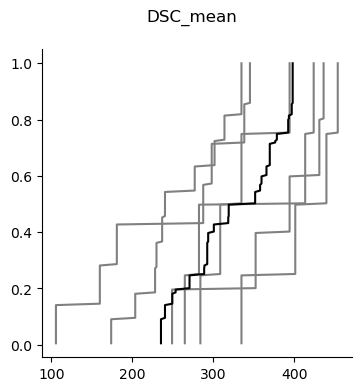

In [18]:
#select property to plot [mean, lenght, distance]
parameter='mean'
df= summary_dsc(ExMdata, parameter)

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("DSC_"+parameter)
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

#ax.set_xlim([100,500])
print(f"{parameter} mean = {df.transpose().mean().mean()} +- sem {df.transpose().mean().sem()} count {df.melt().count().value}")


### Create figure panels for Fig. 1 
Fig. 1j Compartment length

mean mean = 17.219299095299224 +- sem 1.5486910114411279 count 35


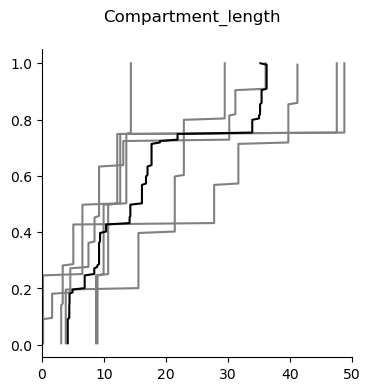

In [7]:
df= summary_compt(ExMdata, 'length')

# plot the cumulative histogram for each dendrite
n_bins=200
n, bins, patches = plt.hist(df.transpose(), n_bins, density=True, histtype='step', cumulative=True)
# Close the plot to suppress it
plt.close()

avg_df, bins = avgCDF(df, patches, n_bins, n)

fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle("Compartment_length")
ax.plot(avg_df.iloc[:, :-1], bins, color='grey')
ax.plot(avg_df.iloc[:, len(avg_df.columns)-1], bins, color='black')

ax.set_xlim([0,50])
print(f"{parameter} mean = {df.transpose().mean().mean()} +- sem {df.transpose().mean().sem()} count {df.melt().count().value}")


### Select dendrite and branch to analyse
Example dendrite shown in Supplemental Fig. 1b 

In [8]:
#data, dendrite branch
dend_name= 'C1_03_cell2_d3'  #'dendrite3' #'dendrite1' 'dendrite4' #'C1_02_cell1_d2'   #'C1_03_cell2_d2' 'C1_03_cell2_d3'
branchNo= 3
#branchs=dendbranch_dic[dend_name]
df=ExMdata[dend_name]['DSC_properties']

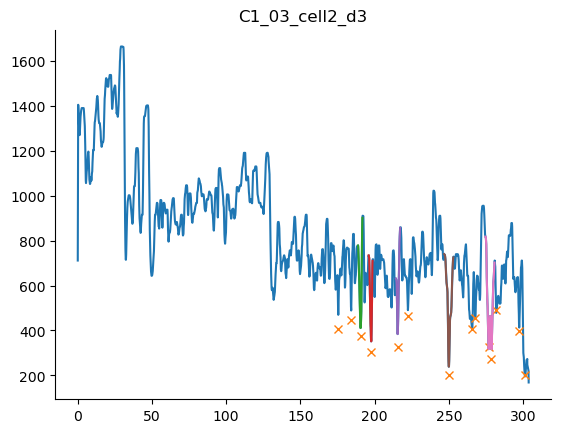

In [9]:
fig, ax = plot_dsc(ExMdata[dend_name],dend_name, corr=1)  

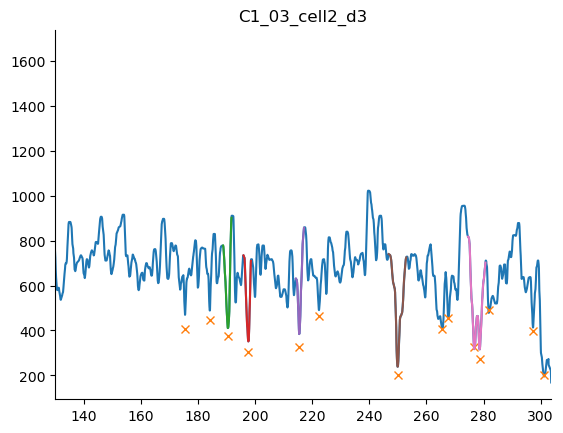

In [10]:
#sets start and end points of branch
strt = ExMdata[dend_name]['branchNo'][branchNo][1]

if branchNo + 1 < len(ExMdata[dend_name]['branchNo']) and ExMdata[dend_name]['branchNo'][branchNo+1] in ExMdata[dend_name]['branchNo']:
    end = ExMdata[dend_name]['branchNo'][branchNo+1][1]
else:
    end = (ExMdata[dend_name]['data']['length'].iloc[-1] * 
           ExMdata[dend_name]['res'] / 
           ExMdata[dend_name]['ex_factor'])

ax.set_xlim(strt, end)
fig

### Create figure panels for supplemental Fig. 1
Example dendrite shown in Supplemental Fig. 1b 

,0,1,2,3,4,5
0,1630.072996,588.645519,379.285764,NaN,NaN,NaN
1,1313.803651,507.491576,383.977280,322.172066,NaN,NaN
2,1048.311016,1053.488418,698.335061,NaN,NaN,NaN
3,2372.861842,1297.183797,1295.398424,636.993040,NaN,NaN
4,1360.733606,1056.839729,983.792930,855.878450,678.920219,640.856919
5,1352.237614,1055.671551,968.333786,666.618581,NaN,NaN


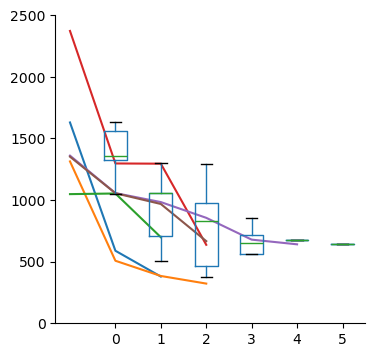

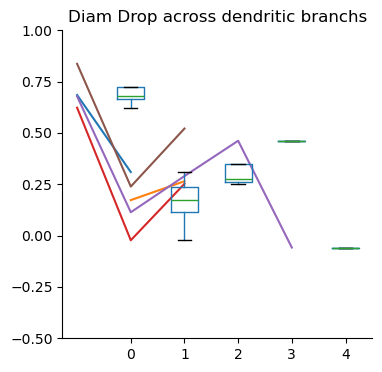

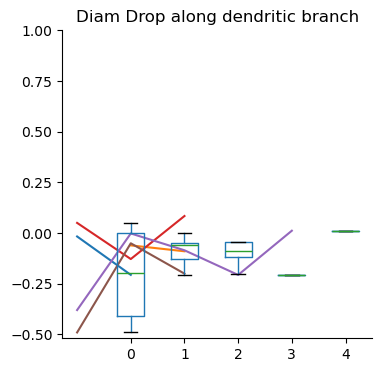

In [11]:
from plots import branch_figs
branch_figs(ExMdata, plot_path)

### Calculate Resistances for DSCs and dendritic shafts
Resistance values estimated from morphology (see [Tonnesen et al. 2014](https://pubmed.ncbi.nlm.nih.gov/24657968/) ) using 
Rmorph = (p x L) / A
p= resistivity of 181 Ohms cm
L = length 
A = cross sectional area

In [15]:
from Branch_analysis import resistance_branch, compile_resistances

dendbranch_dic={'dendrite1': [1,2],'dendrite3':[1,2,3], 'dendrite4':[2], 'C1_02_cell1_d2':[3], 'C1_03_cell2_d2':[5],'C1_03_cell2_d3':[3]}

resistance_branch(dendbranch_dic, ExMdata)
Rdend_data, Rmorph_data, length_data = compile_resistances(ExMdata)

plot resistances

Dend resisitance per micron resistance    5.577656
dtype: float64 SEM resistance    1.925162
dtype: float64 count resistance    6
dtype: int64
DSC resisitance per mircon resistance    34.371693
dtype: float64 SEM resistance    5.968993
dtype: float64 count dendrite      35
resistance    35
dtype: int64
Sum DSC resisitance per dendrite resitance    259.728778
dtype: float64 SEM resitance    113.787012
dtype: float64 count resitance    6
dtype: int64


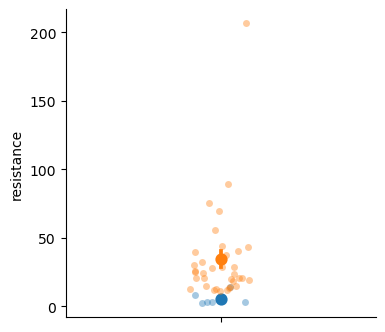

In [17]:
df = pd.concat(Rdend_data)
df = df.reset_index(level=0)
df = df.rename(columns={'level_0': 'dendrite'})

grp_df = df.groupby('dendrite').mean(numeric_only=True)

fig, ax =plt.subplots(figsize=(4, 4))
ax=sns.stripplot(y='resistance', alpha=0.4, data=grp_df)
ax=sns.pointplot(y='resistance', linestyle='none', errorbar='se',data=grp_df)

print(f"Dend resisitance per micron {grp_df.mean(numeric_only=True)} SEM {grp_df.sem(numeric_only=True)} count {grp_df.count()}")

# Create the DataFrame
df = pd.DataFrame(Rmorph_data, columns=['dendrite', 'resistance'])
length_df = pd.DataFrame(length_data, columns=['dendrite', 'length'])

ax=sns.stripplot(y='resistance', alpha=0.4, data=df)
ax=sns.pointplot(y='resistance', linestyle='none', errorbar='se',data=df)

print(f"DSC resisitance per mircon {df.mean(numeric_only=True)} SEM {df.sem(numeric_only=True)} count {df.count()}")

ResisTotal={'resitance':length_df.length*df.resistance, 'dendrite': df.dendrite}
df=pd.DataFrame(ResisTotal)

grp_df = df.groupby('dendrite').sum(numeric_only=True)
print(f"Sum DSC resisitance per dendrite {grp_df.mean(numeric_only=True)} SEM {grp_df.sem(numeric_only=True)} count {grp_df.count()}")
